# Step 12: Repeated runs (mean and standard deviation over seeds)

**Question:** several of our models contain randomness (Decision Tree, Random Forest, AdaBoost, Gradient Boosting, and
the stack/soft vote that use them). Were the earlier results just lucky draws of the random seed?

**Method**
- Nine of the ten models of Step 10 (the tuned family models chosen by validation score, plus the stack and soft vote;
  the untuned SVM is left out because it is the same deterministic model as the tuned SVM family),
  each run with **10 different seeds (0-9)** on the time-aware protocol A (train on batches 1-3, test on 4-10).
- Only the algorithms' own randomness changes (random seed of trees, bootstrap samples, ...). The train/test
  split is always the same.
- The earlier steps used seed 42. We check how that single run compares with the 10 new ones.
- **What this does NOT measure:** variation from *which* samples were in the test set (Step 10's bootstrap covered that)
  and variation from choosing a different training period (we only have one: batches 1-3).

In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 170)

def read(name):
    # keep_default_na=False: otherwise pandas turns the text "None" (no reduction) into a missing value
    return pd.read_csv(f"../results/{name}", keep_default_na=False)

runs = read("step12_repeated_runs.csv")
MODELS = ["Soft vote", "SVM", "Stack (LR)", "Random Forest + PCA", "Gradient Boosting + PCA", "AdaBoost + PCA",
          "kNN + PCA", "Naive Bayes + PCA", "Decision Tree"]
assert set(runs["model"]) == set(MODELS) and runs["seed"].nunique() == 10, "results incomplete"
pooled = runs[runs["test_batch"] == "pooled"]
print("seeds:", sorted(pooled["seed"].unique()), "| models:", len(MODELS), "| rows:", len(runs))

seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)] | models: 9 | rows: 720


## 1. Pooled accuracy over 10 seeds

In [2]:
acc = pooled.pivot(index="seed", columns="model", values="accuracy")[MODELS] * 100
f1 = pooled.pivot(index="seed", columns="model", values="macro_f1")[MODELS] * 100

# the single seed-42 results reported in Steps 8 and 9
s8 = read("step8_tuned_protocolA.csv"); s8 = s8[s8["test_batch"] == "pooled"].set_index(["model", "reduction"])
s9 = read("step9_stacking_metrics.csv"); s9 = s9[(s9["protocol"] == "A") & (s9["test_batch"] == "pooled")].set_index("model")
best = read("step8_best_params.csv")
ref42 = {}
for m in MODELS:
    if m in ("Stack (LR)", "Soft vote"):
        ref42[m] = s9.loc[m, "accuracy"] * 100
    else:
        fam, _, red = m.partition(" + ")
        ref42[m] = s8.loc[(fam, red or "None"), "accuracy"] * 100

summary = pd.DataFrame({
    "mean accuracy %": acc.mean(), "std (points)": acc.std(ddof=1),
    "min %": acc.min(), "max %": acc.max(), "seed-42 run %": pd.Series(ref42),
    "mean macro-F1 %": f1.mean(), "macro-F1 std": f1.std(ddof=1),
})
summary["range (points)"] = summary["max %"] - summary["min %"]
summary.round(2).to_csv("../results/step12_summary.csv")
summary.round(2)

,mean accuracy %,std (points),min %,max %,seed-42 run %,mean macro-F1 %,macro-F1 std,range (points)
Soft vote,75.47,0.14,75.30,75.70,75.33,75.54,0.15,0.41
SVM,73.19,0.00,73.19,73.19,73.19,74.55,0.00,0.00
Stack (LR),69.52,0.40,69.05,70.18,70.16,70.56,0.26,1.14
Random Forest + PCA,69.92,0.59,69.18,70.89,69.53,67.37,0.62,1.71
Gradient Boosting + PCA,67.74,0.03,67.68,67.79,67.71,67.12,0.03,0.10
AdaBoost + PCA,66.21,0.00,66.21,66.21,66.21,64.64,0.00,0.00
kNN + PCA,64.90,0.00,64.90,64.90,64.90,66.30,0.00,0.00
Naive Bayes + PCA,51.36,0.00,51.36,51.36,51.36,50.52,0.00,0.00
Decision Tree,52.59,1.54,50.49,55.41,49.68,48.74,1.43,4.92


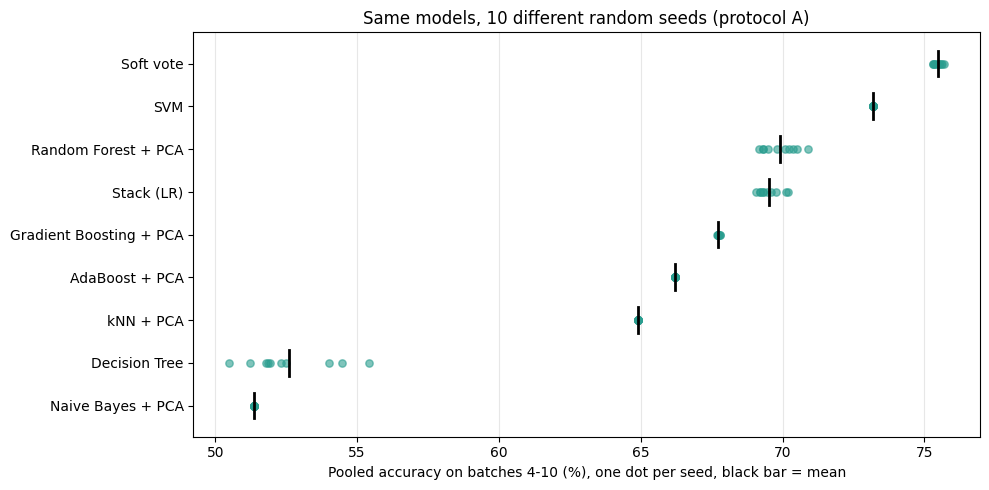

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
order = summary.sort_values("mean accuracy %").index
for i, m in enumerate(order):
    ax.scatter(acc[m], [i] * len(acc), color="#2a9d8f", alpha=0.6, s=28, zorder=3)
    ax.plot([summary.loc[m, "mean accuracy %"]] * 2, [i - 0.3, i + 0.3], color="black", lw=2, zorder=4)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel("Pooled accuracy on batches 4-10 (%), one dot per seed, black bar = mean")
ax.set_title("Same models, 10 different random seeds (protocol A)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("../results/step12_seed_spread.png", dpi=150)
plt.show()

**What to notice (pooled accuracy on batches 4-10, mean +/- standard deviation over 10 seeds):**

| Model | Mean | Std (points) | Range |
|---|---|---|---|
| Soft vote | 75.5% | 0.14 | 75.3 - 75.7 |
| SVM | 73.2% | 0.00 | 73.2 - 73.2 |
| Random Forest + PCA | 69.9% | 0.59 | 69.2 - 70.9 |
| Stack (LR) | 69.5% | 0.40 | 69.1 - 70.2 |
| Gradient Boosting + PCA | 67.7% | 0.03 | 67.7 - 67.8 |
| AdaBoost + PCA | 66.2% | 0.00 | 66.2 - 66.2 |
| kNN + PCA | 64.9% | 0.00 | 64.9 - 64.9 |
| Decision Tree | 52.6% | 1.54 | 50.5 - 55.4 |
| Naive Bayes + PCA | 51.4% | 0.00 | 51.4 - 51.4 |

- **Most models are not affected by the seed at all:** SVM, kNN, Naive Bayes and AdaBoost (with these settings) give
  identical results every time (std 0), and Gradient Boosting varies by only 0.03 points.
- **The main results are stable.** The soft vote (the best model) varies by +/-0.14 points, the stack by 0.4 and Random
  Forest by 0.6. The single seed-42 runs from Steps 8-10 are inside these ranges (soft vote 75.3%, Random Forest 69.5%);
  the stack's seed-42 run (70.2%) was at the top of its range, so a typical stack result is **69.5%**, about 0.6 points lower
  than reported in Step 9.
- **The Decision Tree is the one unstable model.** Its 10 seeds range from 50.5% to 55.4% (std 1.5), and its seed-42 run
  (49.7%) was lower than all ten. So its earlier number understated its typical level by about 3 points. It is still among
  the weakest, but the order of the two worst models is not reliable: the Decision Tree's range (50.5 - 55.4) covers Naive Bayes + PCA (51.4%).

## 2. Does the seed change who wins?

In [4]:
d = pd.DataFrame({
    "soft vote minus SVM (points)": acc["Soft vote"] - acc["SVM"],
    "stack minus SVM (points)": acc["Stack (LR)"] - acc["SVM"],
    "random forest minus SVM (points)": acc["Random Forest + PCA"] - acc["SVM"],
})
out = pd.DataFrame({"mean": d.mean(), "min": d.min(), "max": d.max(),
                    "seeds where model is above SVM (of 10)": (d > 0).sum()})
out.round(2)

,mean,min,max,seeds where model is above SVM (of 10)
soft vote minus SVM (points),2.28,2.11,2.51,10
stack minus SVM (points),-3.67,-4.14,-3.01,0
random forest minus SVM (points),-3.27,-4.01,-2.30,0


**What to notice:** the soft vote beats the tuned SVM in **all 10 seeds**, by 2.1 to 2.5 points (mean +2.3), while the
stack and Random Forest + PCA are below the SVM in all 10 seeds (by 3.0 to 4.1, and 2.3 to 4.0 points). So the random seed
is far too small to change the ranking of the top models.

**Remember the limit of this check:** it only varies the algorithm's randomness. The caution from Step 10 still stands: batch by
batch the soft vote beats the SVM on 3 batches, loses on 3 and ties on 1, and its pooled lead comes mostly from batch 10.

## 3. Per batch

In [5]:
per = runs[runs["test_batch"] != "pooled"].assign(b=lambda x: x["test_batch"].astype(int))
mean_b = per.pivot_table(index="model", columns="b", values="accuracy", aggfunc="mean").loc[MODELS] * 100
std_b = per.pivot_table(index="model", columns="b", values="accuracy", aggfunc=lambda s: s.std(ddof=1)).loc[MODELS] * 100
print("Standard deviation over seeds of the accuracy on each batch (percentage points)")
std_b.round(2)

Standard deviation over seeds of the accuracy on each batch (percentage points)


b,4,5,6,7,8,9,10
model,,,,,,,
Soft vote,1.87,0.00,0.19,0.26,0.73,0.34,0.17
SVM,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Stack (LR),1.58,0.26,0.20,1.00,0.50,1.28,0.35
Random Forest + PCA,0.89,0.48,1.24,0.72,3.90,0.53,1.21
Gradient Boosting + PCA,0.00,0.00,0.00,0.00,0.00,0.00,0.09
AdaBoost + PCA,0.00,0.00,0.00,0.00,0.00,0.00,0.00
kNN + PCA,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Naive Bayes + PCA,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Decision Tree,4.90,1.46,6.23,1.64,13.25,5.85,2.74


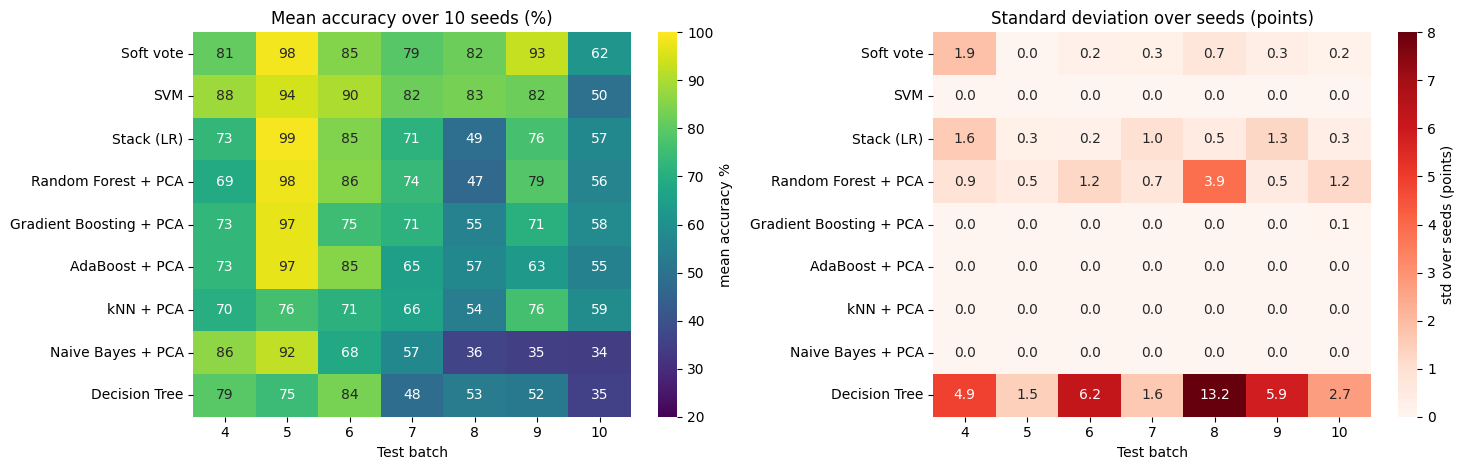

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(mean_b, annot=True, fmt=".0f", cmap="viridis", vmin=20, vmax=100, ax=axes[0], cbar_kws={"label": "mean accuracy %"})
axes[0].set_title("Mean accuracy over 10 seeds (%)"); axes[0].set_xlabel("Test batch"); axes[0].set_ylabel("")
sns.heatmap(std_b, annot=True, fmt=".1f", cmap="Reds", vmin=0, vmax=8, ax=axes[1], cbar_kws={"label": "std over seeds (points)"})
axes[1].set_title("Standard deviation over seeds (points)"); axes[1].set_xlabel("Test batch"); axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("../results/step12_per_batch.png", dpi=150)
plt.show()

**What to notice:** per batch, the deterministic models have a standard deviation of 0, and Gradient Boosting + PCA is at
most 0.09. Random Forest varies most on batch 8 (3.9 points; it has only 276 samples) and by at most 1.2 on the other
batches. The stack varies by up to 1.6 points (batch 4) and the soft vote by up to 1.9 (batch 4, 161 samples). The **Decision Tree** is very
unstable batch by batch: up to 13.3 points on batch 8, and 4.9 to 6.2 on batches 4, 6 and 9, so its per-batch results from
earlier steps should not be trusted individually. As in Step 10, the small batches (4, 8, 9) are the noisiest.

## Summary of Step 12
- Ten seeds were run for nine models on protocol A. **Four of them (SVM, kNN, Naive Bayes, AdaBoost) are completely
  deterministic here, and Gradient Boosting varies by 0.03 points.**
- **The headline results are stable:** soft vote 75.5% +/- 0.14, SVM 73.2%, Random Forest + PCA 69.9% +/- 0.6,
  stack 69.5% +/- 0.4. The ranking of the top models does not depend on the seed (the soft vote beats SVM in 10 of 10 seeds,
  the stack is below it in 10 of 10).
- **Two corrections to earlier single-seed numbers:** the stack's typical accuracy is 69.5% (Step 9 showed 70.2%), and the
  Decision Tree's typical accuracy is about 52.6% (earlier 49.7%). From here on we report mean +/- std for these models.
- **Limit:** seed variation is only the algorithms' own randomness. It does not capture variation from the choice of test samples
  (Step 10) or from the choice of training period (only batches 1-3 are used).